# Mini-Project 1 – Fetching and Displaying a Weather Forecast with Python Web APIs

**OOP with Python, Assignment 2 (Advent 2026)** · Wesonga John Collins

Location name → coordinates (Open-Meteo Geocoding) → daily forecast (Open-Meteo Forecast) → table, summary
and chart, with MET Norway Locationforecast 2.0 as a second source. Reusable code lives in `src/a2/weather/`;
offline tests of the parsing functions use saved real responses in `tests/data/`.

*Weather data by Open-Meteo.com (CC BY 4.0) and MET Norway (CC BY 4.0).*

## Configuration — the only manual input

Set `LOCATION` (and `CANDIDATE_INDEX` if the name is ambiguous). The contact email is **not** written here: it is
read from the environment variable `A2_CONTACT_EMAIL`, set in the Command Prompt before starting Jupyter
(`set A2_CONTACT_EMAIL=you@university.ac.ug`). The code refuses to send any request while only the placeholder is
set, so it never invents contact details.

In [1]:
import os
from a2.weather.config import ENV_VAR, PLACEHOLDER

LOCATION = "Kampala"                 # place to forecast
CANDIDATE_INDEX = 0                  # which geocoding candidate to use (0 = best match); None = refuse ambiguous names
FORECAST_DAYS = 7                    # 1-16
CONTACT_EMAIL = os.environ.get(ENV_VAR, PLACEHOLDER)

In [2]:
import time
import urllib.parse
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import requests

from a2.weather.cache import ResponseCache
from a2.weather.config import user_agent
from a2.weather.errors import (AmbiguousLocationError, InvalidCoordinatesError,
                               LocationNotFoundError, RequestFailedError, WeatherError)
from a2.weather.forecast import FORECAST_URL, forecast_to_dataframe, get_forecast, summarise
from a2.weather.geocoding import GEOCODING_URL, choose_location, geocode, geocode_urllib
from a2.weather.http import RetryPolicy, fetch, get_json
from a2.weather.metno import get_metno, metno_to_daily

UA = user_agent(CONTACT_EMAIL)                      # raises ConfigurationError if the email is not set
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
CACHE = ResponseCache(ROOT / ".cache" / "weather", default_ttl=3600)
print("User-Agent set (contact email hidden). Cache folder:", CACHE.directory.relative_to(ROOT))

User-Agent set (contact email hidden). Cache folder: .cache\weather


### Libraries outside the brief's allowed list (one-line justifications)

| Import | Why |
|---|---|
| `dataclasses`, `typing`, `collections.abc` (standard library) | `Location`/`RetryPolicy` records and type hints, which the brief requires |
| `re` (standard library) | validating the contact email before it is sent |
| `pathlib`, `hashlib`, `email.utils` (standard library) | cache extension: file paths, cache keys, and parsing MET Norway's `Expires` header |
| `pytest` (tests only, not used in the notebook) | runs the offline parsing tests |

## Part A – HTTP fundamentals

### A1. Standard library only (`urllib.request`, `urllib.parse`, `json`)

In [3]:
query = urllib.parse.urlencode({"name": "Dresden", "count": 3, "language": "en", "format": "json"})
print("Query string built with urlencode:", query)

result = geocode_urllib("Dresden", count=3, user_agent=UA)
best = result["data"]["results"][0]
print(f"HTTP {result['status']} | {result['content_type']} | {result['seconds'] * 1000:.0f} ms")
print(f"Best match: {best['name']}, {best.get('admin1', '')}, {best['country']} "
      f"({best['latitude']:.4f}, {best['longitude']:.4f}), timezone {best['timezone']}")

Query string built with urlencode: name=Dresden&count=3&language=en&format=json


HTTP 200 | application/json; charset=utf-8 | 943 ms
Best match: Dresden, Saxony, Germany (51.0509, 13.7383), timezone Europe/Berlin


### A2. The same call with `requests` (`params=` and a timeout)

In [4]:
response = requests.get(GEOCODING_URL, params={"name": "Dresden", "count": 3, "language": "en", "format": "json"},
                        headers={"User-Agent": UA}, timeout=10)
response.raise_for_status()
best = response.json()["results"][0]
print("Final URL:", response.url)
print(f"Best match: {best['name']}, {best['country']} ({best['latitude']:.4f}, {best['longitude']:.4f})")

Final URL: https://geocoding-api.open-meteo.com/v1/search?name=Dresden&count=3&language=en&format=json
Best match: Dresden, Germany (51.0509, 13.7383)


### A3. Comparing the two approaches

| Aspect | `urllib` (standard library) | `requests` |
|---|---|---|
| Code length | Build the query with `urlencode`, wrap it in a `Request`, open it in a `with` block, read bytes, decode them, then `json.loads` — about six steps | One `requests.get(url, params=..., timeout=...)` call and `.json()` |
| Error handling | Raises `HTTPError` for 4xx/5xx and `URLError` for network problems; status handling is manual | `raise_for_status()` turns 4xx/5xx into `HTTPError` on request; separate `ConnectionError` and `Timeout` classes make retries easy |
| Headers | Passed in the `Request(headers=...)` constructor; response headers via `response.headers` | `headers=` argument; response headers in a case-insensitive dictionary |
| Encoding | The body is raw bytes; the charset must be read from `Content-Type` and decoded by hand | Decodes text using the declared charset automatically; `.json()` parses directly |
| Dependencies | None — always available | Third-party package (but the brief allows it) |

`urllib` gives complete control with nothing to install; `requests` removes boilerplate and makes errors and
timeouts explicit, which is why the rest of the project uses it through one robust wrapper (`fetch`).

### A4. Status code, Content-Type and response time of one request

In [5]:
start = time.perf_counter()
r = requests.get(GEOCODING_URL, params={"name": "Dresden", "count": 1}, headers={"User-Agent": UA}, timeout=10)
wall = time.perf_counter() - start
pd.DataFrame({"value": {"status code": r.status_code,
                        "Content-Type": r.headers.get("Content-Type"),
                        "server time to response headers (requests .elapsed)": f"{r.elapsed.total_seconds() * 1000:.0f} ms",
                        "total wall-clock time incl. body": f"{wall * 1000:.0f} ms",
                        "body size": f"{len(r.content):,} bytes"}})

,value
status code,200
Content-Type,application/json; charset=utf-8
server time to response headers (requests .elapsed),772 ms
total wall-clock time incl. body,776 ms
body size,398 bytes


## Part B – Forecast retrieval and display

### B1. Geocoding with candidate selection

`geocode()` returns a list of candidates; an absent `results` key gives an empty list. `choose_location()` picks the
candidate set by `CANDIDATE_INDEX`, or — with `None` — refuses ambiguous names and lists the options.

In [6]:
candidates = geocode(LOCATION, count=5, user_agent=UA, cache=CACHE)
display(pd.DataFrame([vars(c) for c in candidates]).rename_axis("index"))
place = choose_location(LOCATION, candidates, CANDIDATE_INDEX)
print("Selected:", place)

,name,latitude,longitude,country,admin1,timezone,population
index,,,,,,,
0,Kampala,0.31628,32.58219,Uganda,Central Region,Africa/Kampala,1680600.0
1,Kampala,7.32344,-7.68519,Ivory Coast,Montagnes,Africa/Abidjan,462.0
2,Kampala,2.30086,30.59269,Democratic Republic of Congo,Ituri,Africa/Lubumbashi,NaN
3,Kampala,-2.19509,27.74864,Democratic Republic of Congo,South Kivu,Africa/Lubumbashi,NaN
4,Kampala,-14.41129,31.60980,Zambia,Eastern Province,Africa/Lusaka,NaN


Selected: Kampala, Central Region, Uganda (0.3163, 32.5822)


In [7]:
# An ambiguous name: list the candidates and let the configuration decide.
springfields = geocode("Springfield", count=5, user_agent=UA, cache=CACHE)
try:
    choose_location("Springfield", springfields, index=None)
except AmbiguousLocationError as err:
    print("AmbiguousLocationError:", err)
print("\nWith CANDIDATE_INDEX = 1 ->", choose_location("Springfield", springfields, index=1))

AmbiguousLocationError: 'Springfield' matches 5 places. Set CANDIDATE_INDEX to one of: [0] Springfield, Missouri, United States (37.2153, -93.2982); [1] Springfield, Illinois, United States (39.8017, -89.6437); [2] Springfield, Massachusetts, United States (42.1015, -72.5898); [3] Springfield, Ohio, United States (39.9242, -83.8088); [4] Springfield, Tennessee, United States (36.5092, -86.8850)

With CANDIDATE_INDEX = 1 -> Springfield, Illinois, United States (39.8017, -89.6437)


### B2–B3. Daily forecast as a DataFrame with units and readable weather

In [8]:
raw = get_forecast(place.latitude, place.longitude, FORECAST_DAYS, user_agent=UA, timezone="auto", cache=CACHE)
forecast = forecast_to_dataframe(raw)
print(f"Timezone returned by the API: {raw['timezone']} (UTC offset {raw['utc_offset_seconds'] // 3600:+d} h)")

Timezone returned by the API: Africa/Kampala (UTC offset +3 h)


### B4. Text summary, formatted table and chart

In [9]:
print(summarise(forecast, str(place)))
forecast.style.format(precision=1).set_caption(f"Daily forecast for {place.name} — Weather data by Open-Meteo.com (CC BY 4.0)")

Kampala, Central Region, Uganda (0.3163, 32.5822), 2026-10-16 to 2026-10-22 (7 days, Africa/Kampala): highs 24.3–27.6 °C, lows 17.9–18.7 °C; total precipitation 76.9 mm, wettest day 2026-10-17 (23.0 mm, violent rain showers). Weather data by Open-Meteo.com (CC BY 4.0).


,Weather,Max temp (°C),Min temp (°C),Precipitation (mm),Max wind (km/h)
Date,,,,,
2026-10-16,Moderate rain showers,26.6,17.9,16.9,18.4
2026-10-17,Violent rain showers,24.3,18.1,23.0,13.4
2026-10-18,Slight rain showers,27.6,18.3,4.8,7.2
2026-10-19,Moderate rain showers,26.8,18.7,10.9,8.6
2026-10-20,Slight rain showers,27.1,18.7,10.2,9.6
2026-10-21,Dense drizzle,27.6,18.6,7.5,10.2
2026-10-22,Moderate drizzle,26.8,18.7,3.6,9.2


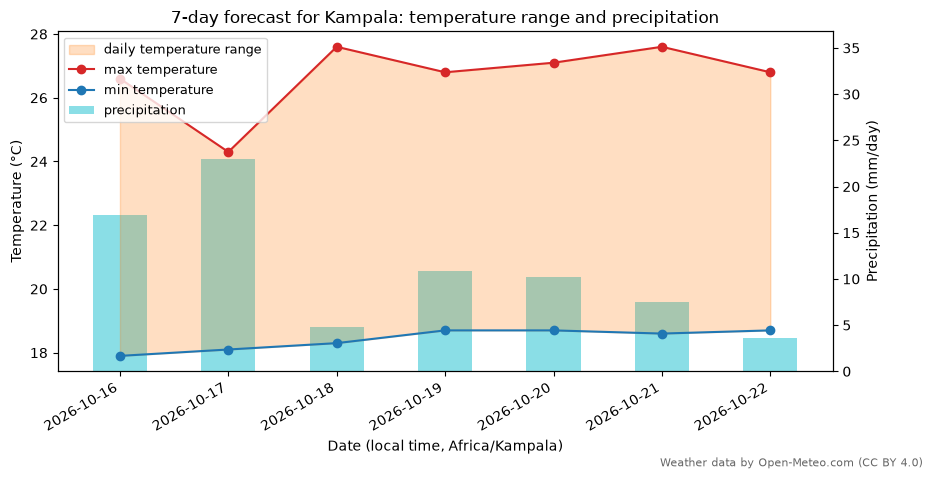

In [10]:
days = pd.to_datetime(forecast.index)
tmax, tmin = forecast["Max temp (°C)"], forecast["Min temp (°C)"]
fig, ax = plt.subplots(figsize=(10, 5))
ax.fill_between(days, tmin, tmax, color="tab:orange", alpha=0.25, label="daily temperature range")
ax.plot(days, tmax, "o-", color="tab:red", label="max temperature")
ax.plot(days, tmin, "o-", color="tab:blue", label="min temperature")
ax.set_ylabel("Temperature (°C)")
ax.set_xlabel(f"Date (local time, {raw['timezone']})")
ax2 = ax.twinx()
ax2.bar(days, forecast["Precipitation (mm)"], width=0.5, color="tab:cyan", alpha=0.5, label="precipitation")
ax2.set_ylabel("Precipitation (mm/day)")
ax2.set_ylim(0, max(5, forecast["Precipitation (mm)"].max() * 1.6))
ax.set_zorder(ax2.get_zorder() + 1)   # draw the temperature lines in front of the bars
ax.patch.set_visible(False)
handles = ax.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
labels = ax.get_legend_handles_labels()[1] + ax2.get_legend_handles_labels()[1]
ax.legend(handles, labels, loc="upper left", fontsize=9)
ax.set_title(f"{FORECAST_DAYS}-day forecast for {place.name}: temperature range and precipitation")
fig.text(0.99, 0.01, "Weather data by Open-Meteo.com (CC BY 4.0)", ha="right", fontsize=8, color="0.4")
fig.autofmt_xdate()
plt.show()

## Part C – Robustness and a second source

Every request goes through `fetch()` (in `src/a2/weather/http.py`): timeout, `raise_for_status()`, retries on
connection errors, timeouts, HTTP 429 and 5xx with exponential back-off (0.5, 1, 2 … s, capped at 8 s, at most 4
attempts), and a `RequestFailedError` when it gives up. Client errors such as 400/404 are not retried, because
repeating a bad request cannot fix it.

### C2. Deliberately broken inputs

In [11]:
# 1. Invalid city: the API answers 200 with no "results" key.
try:
    choose_location("Qzxqzxqzx", geocode("Qzxqzxqzx", user_agent=UA), CANDIDATE_INDEX)
except LocationNotFoundError as err:
    print("Invalid city ->", type(err).__name__, ":", err)

# 2a. Invalid latitude caught before any request is sent.
try:
    get_forecast(100, 32.58, 7, user_agent=UA)
except InvalidCoordinatesError as err:
    print("Invalid latitude (client check) ->", type(err).__name__, ":", err)

# 2b. The same latitude sent anyway: the server rejects it with 400, which is not retried.
try:
    fetch(FORECAST_URL, {"latitude": 100, "longitude": 32.58, "daily": "temperature_2m_max"},
          headers={"User-Agent": UA})
except RequestFailedError as err:
    print("Invalid latitude (server)       ->", type(err).__name__, ":", err)

Invalid city -> LocationNotFoundError : No location found for 'Qzxqzxqzx'
Invalid latitude (client check) -> InvalidCoordinatesError : latitude 100 is outside -90..90


Invalid latitude (server)       -> RequestFailedError : Request to https://api.open-meteo.com/v1/forecast failed after 1 attempt(s): HTTP 400


In [12]:
# 3. No network (simulated): a session object whose every request raises ConnectionError.
class OfflineSession:
    def get(self, url, **kwargs):
        raise requests.ConnectionError("simulated: network unreachable")

waits = []
try:
    fetch(FORECAST_URL, {"latitude": 0.35, "longitude": 32.58}, session=OfflineSession(), sleep=waits.append)
except RequestFailedError as err:
    print("No network ->", type(err).__name__, ":", err)
print("Back-off delays that would have been waited (s):", waits)

# 4. Tiny timeout against the real server (two quick attempts, short delay).
try:
    fetch(FORECAST_URL, {"latitude": 0.35, "longitude": 32.58, "daily": "temperature_2m_max"},
          headers={"User-Agent": UA}, timeout=0.0001, policy=RetryPolicy(max_attempts=2, base_delay=0.2))
except RequestFailedError as err:
    print("Tiny timeout ->", type(err).__name__, ":", err)

No network -> RequestFailedError : Request to https://api.open-meteo.com/v1/forecast failed after 4 attempt(s): connection error (ConnectionError)
Back-off delays that would have been waited (s): [0.5, 1.0, 2.0]


Tiny timeout -> RequestFailedError : Request to https://api.open-meteo.com/v1/forecast failed after 2 attempt(s): timed out after 0.0001 s (ConnectTimeout)


### Second source: MET Norway Locationforecast 2.0

MET Norway returns an hourly (later 6-hourly) series. It is aggregated to local calendar days and compared with
Open-Meteo for the same coordinates. Wind is converted from m/s to km/h.

In [13]:
met_raw = get_metno(place.latitude, place.longitude, user_agent=UA, cache=CACHE)
met_daily = metno_to_daily(met_raw, raw["timezone"])
common = forecast.index.intersection(met_daily.index)
compare = pd.DataFrame({
    "Open-Meteo max (°C)": forecast.loc[common, "Max temp (°C)"],
    "MET max (°C)": met_daily.loc[common, "Max temp (°C)"],
    "Open-Meteo min (°C)": forecast.loc[common, "Min temp (°C)"],
    "MET min (°C)": met_daily.loc[common, "Min temp (°C)"],
    "Open-Meteo rain (mm)": forecast.loc[common, "Precipitation (mm)"],
    "MET rain (mm)": met_daily.loc[common, "Precipitation (mm)"],
    "MET hours covered": met_daily.loc[common, "Hours covered"],
})
print("MET Norway data updated at:", met_raw["properties"]["meta"]["updated_at"], "(CC BY 4.0)")
compare.round(1)

MET Norway data updated at: 2026-10-16T13:17:22Z (CC BY 4.0)


,Open-Meteo max (°C),MET max (°C),Open-Meteo min (°C),MET min (°C),Open-Meteo rain (mm),MET rain (mm),MET hours covered
Date,,,,,,,
2026-10-16,26.6,25.6,17.9,20.6,16.9,0.1,7.0
2026-10-17,24.3,23.8,18.1,18.3,23.0,16.2,24.0
2026-10-18,27.6,27.1,18.3,18.4,4.8,5.8,24.0
2026-10-19,26.8,24.2,18.7,18.9,10.9,7.2,27.0
2026-10-20,27.1,23.2,18.7,20.2,10.2,11.9,24.0
2026-10-21,27.6,25.2,18.6,19.4,7.5,3.3,24.0
2026-10-22,26.8,26.7,18.7,19.4,3.6,1.9,24.0


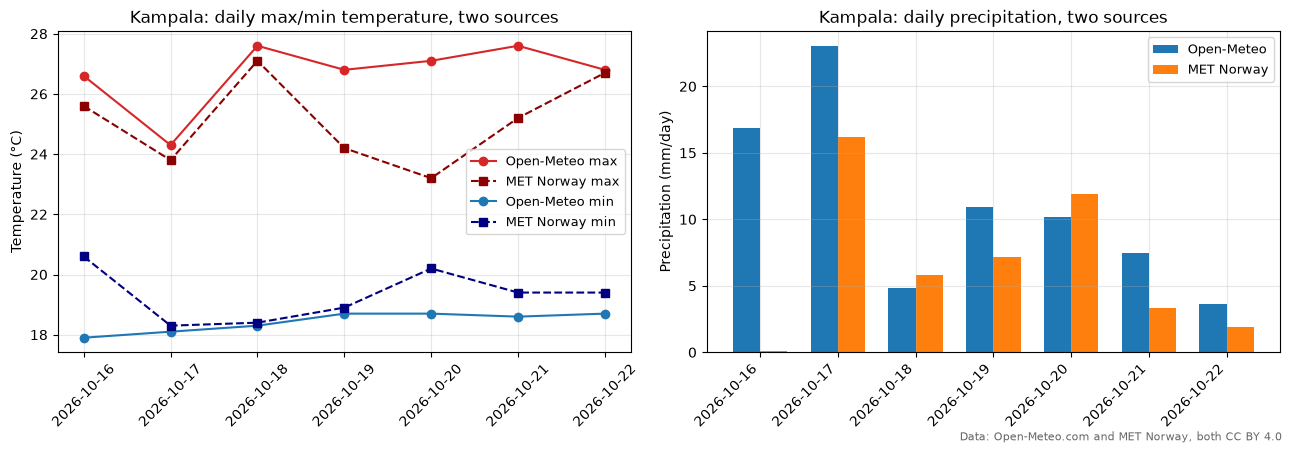

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
d = pd.to_datetime(compare.index)
axes[0].plot(d, compare["Open-Meteo max (°C)"], "o-", color="tab:red", label="Open-Meteo max")
axes[0].plot(d, compare["MET max (°C)"], "s--", color="darkred", label="MET Norway max")
axes[0].plot(d, compare["Open-Meteo min (°C)"], "o-", color="tab:blue", label="Open-Meteo min")
axes[0].plot(d, compare["MET min (°C)"], "s--", color="navy", label="MET Norway min")
axes[0].set_ylabel("Temperature (°C)")
axes[0].set_title(f"{place.name}: daily max/min temperature, two sources")
w = 0.35
x = range(len(compare))
axes[1].bar([i - w / 2 for i in x], compare["Open-Meteo rain (mm)"], width=w, label="Open-Meteo")
axes[1].bar([i + w / 2 for i in x], compare["MET rain (mm)"], width=w, label="MET Norway")
axes[1].set_xticks(list(x), [str(i) for i in compare.index], rotation=45, ha="right")
axes[1].set_ylabel("Precipitation (mm/day)")
axes[1].set_title(f"{place.name}: daily precipitation, two sources")
for ax in axes:
    ax.legend(fontsize=9)
    ax.grid(alpha=0.3)
axes[0].tick_params(axis="x", rotation=45)
fig.text(0.99, 0.01, "Data: Open-Meteo.com and MET Norway, both CC BY 4.0", ha="right", fontsize=8, color="0.4")
fig.tight_layout()
plt.show()

**Comparison.** For Kampala the two sources agree closely on temperature: daily maxima differ by at most 1.4 °C (19 October) and otherwise by 0.5 °C or less. MET Norway's minima are 0.1–1.9 °C *higher* and its maxima slightly lower, especially from 19 October onwards. Part of this is my aggregation rather than the forecasts themselves: after about two days MET Norway gives values only every six hours, so the daily maximum and minimum are taken from four instantaneous temperatures and miss the true extremes (the "hours covered" column shows the switch: 27 hours on 18 October, where hourly and 6-hourly steps overlap). Rainfall agrees much less: over the seven days the totals are similar (48.3 mm from Open-Meteo, 45.2 mm from MET Norway), and both put the wettest day on 22 October (17.4 vs 17.3 mm), but on individual days they differ by a factor of two or more (10.1 vs 4.8 mm on 16 October, 6.9 vs 1.6 mm on 20 October). The first day is not comparable for rain, because MET Norway's series started at its 05:21 UTC update and covers only 15 hours. In the tropics, convective showers are hard to place in time, so a planner should treat daily rainfall from either source as indicative and look at totals and patterns rather than single days.

## Extension – response cache to keep traffic low

Identical requests are answered from a local cache (`.cache/weather/`, not committed). MET Norway responses are
kept until the time in their `Expires` header, as its terms ask; Open-Meteo responses for one hour.

In [15]:
t0 = time.perf_counter(); get_forecast(place.latitude, place.longitude, FORECAST_DAYS, user_agent=UA, cache=CACHE)
t_cached = time.perf_counter() - t0
fresh = ResponseCache(ROOT / ".cache" / "weather-demo-fresh"); fresh.clear()
t0 = time.perf_counter(); get_forecast(place.latitude, place.longitude, FORECAST_DAYS, user_agent=UA, cache=fresh)
t_network = time.perf_counter() - t0
print(f"Same forecast from the cache: {t_cached * 1000:.1f} ms  vs  over the network: {t_network * 1000:.0f} ms")
print(f"Cache hits: {CACHE.hits}, misses: {CACHE.misses}")

Same forecast from the cache: 15.0 ms  vs  over the network: 1059 ms
Cache hits: 1, misses: 4


## Part D – Report

### 1. Data flow from user input to displayed forecast

```
 Config cell                       Environment
 LOCATION, CANDIDATE_INDEX,        A2_CONTACT_EMAIL
 FORECAST_DAYS                            |
        |                                 v
        |                     user_agent()  -> refuses the placeholder
        v                                 |
 geocode(name) ---- fetch(): timeout, raise_for_status, retry + back-off ----> Open-Meteo Geocoding
        |                 (optional ResponseCache; RequestFailedError on final failure)
        v
 parse_locations() -> list[Location] -> choose_location(index)   (none -> LocationNotFoundError,
        |                                                          ambiguous -> AmbiguousLocationError)
        v
 get_forecast(lat, lon, days, timezone="auto") -- validate_request() -- fetch() --> Open-Meteo Forecast
        |                                                     \
        v                                                      get_metno() -- fetch() --> MET Norway
 forecast_to_dataframe(): units in column names,                     |
 WMO code -> description                                       metno_to_daily(): hourly/6-hourly -> local days
        |                                                            |
        v                                                            v
 summary text + formatted table + temperature/precipitation chart   two-source comparison table and chart
```

The only manual input is the configuration cell (location, candidate index, number of days); the contact email is read from an environment variable. The name is sent to the geocoder, which returns up to five candidates. For "Kampala" these included places in Uganda, Côte d'Ivoire, the Democratic Republic of Congo and Zambia, so the choice is made explicitly by `CANDIDATE_INDEX` (0, the best match, Kampala in Uganda). The coordinates and `timezone="auto"` are then sent to the forecast API, so the dates returned are local dates (Africa/Kampala, UTC+3). The JSON is converted into a DataFrame whose column names carry the units returned by the API, the WMO weather codes are decoded, and the result is shown as a summary, a table and a chart. In parallel, the same coordinates go to MET Norway, whose time series is aggregated to the same local days for comparison. Every request goes through one function, `fetch()`, and identical requests can be answered from a local cache.

### 2. Licensing and usage terms, and what they mean for a real product

**Open-Meteo.** The free API may be used only for non-commercial purposes, with limits of fewer than 10,000 calls per day, 5,000 per hour and 600 per minute. The data are licensed under CC BY 4.0, which allows reuse but requires attribution ("Weather data by Open-Meteo.com"). For this coursework that is fine: the notebook makes about a dozen requests and shows the attribution in the summary, the table caption and on each chart. For a real product, the free tier would not be allowed at all, because a product is commercial use. The company would need a paid Open-Meteo plan, and it would still have to display the attribution in its interface.

**MET Norway.** Its data are also licensed under CC BY 4.0, so attribution to MET Norway is required. The terms of service add operational duties: every client must send a User-Agent that identifies the application and gives contact details (anonymous or fake identification is not allowed and can be blocked), clients must cache responses and avoid unnecessary repeat requests, and coordinates should not be sent with more than four decimals. My code sends the identifying User-Agent built from my university email, rounds coordinates to four decimals, and keeps MET responses in the cache until the time in their `Expires` header. For a real product, these terms mean the app should not let thousands of phones call MET Norway directly. A backend service should make the calls with one identifying User-Agent, cache aggressively and serve its own users from that cache; otherwise the provider could block the whole application.

Neither free service offers a service-level agreement, so a product that depends on them must handle outages gracefully and show users where the data came from.

### 3. Reliability issues met and how the code handles them

Several problems appeared in practice, and each is handled explicitly rather than allowed to crash the notebook:

* **Variable latency.** The first standard-library request took about 3.4 seconds (connection set-up and name resolution on a cold start), while later requests took about 0.8 seconds. Every request therefore has a timeout, so a slow server cannot hang the program.
* **"No match" is not an HTTP error.** For an invalid city the geocoder still answers HTTP 200 but simply omits the `results` key. `parse_locations()` treats a missing key as an empty list, and `choose_location()` turns that into a clear `LocationNotFoundError`.
* **Ambiguous names.** "Springfield" returned five places in five US states. Without a candidate index the code raises `AmbiguousLocationError` listing them, instead of silently picking one.
* **Invalid input.** A latitude of 100 is rejected locally with `InvalidCoordinatesError` before any request is sent. When the same request is sent anyway, the server answers HTTP 400; `fetch()` does not retry 4xx errors, because repeating a bad request cannot succeed, and raises `RequestFailedError` after one attempt.
* **Network failure and slow responses.** Connection errors, timeouts, HTTP 429 and 5xx responses are retried with exponential back-off (0.5, 1 and 2 seconds, capped at 8 seconds, at most four attempts) and then reported with a custom exception. The "no network" demonstration uses an injected session that always raises `ConnectionError`; the recorded delays were exactly [0.5, 1.0, 2.0], and with a 0.0001-second timeout the real server produced a `ConnectTimeout` on both attempts.
* **Changing data structure.** MET Norway's series is hourly for about two days and six-hourly afterwards. The aggregation reads the precipitation period that matches each step length, so no rain is counted twice, and a "hours covered" column exposes partial days (15 hours on the first day) and overlaps.
* **Sources disagree.** Open-Meteo and MET Norway gave similar temperatures but daily rainfall that differed by a factor of two or more on some days. The code cannot resolve that, so the notebook shows both sources side by side with their coverage, rather than presenting one number as certain.
* **Traffic.** The cache answered a repeated forecast in about 15 ms instead of about 0.8 seconds over the network, which both speeds up re-runs and respects the providers' requests to keep traffic low.

### 4. Privacy implications of sending location queries to third parties

A weather query is a location query. The geocoder receives the place name typed by the user, and both forecast providers receive precise coordinates together with the user's IP address; MET Norway states that it logs IP addresses and requested coordinates. Repeated queries can reveal where a person lives, works or travels, and the requests in this project also carry my university email in the User-Agent, which identifies me personally. Nothing here is secret, but it is personal data being passed to organisations outside Uganda.

The code limits this exposure in three ways: the email is kept out of the repository and committed notebooks (it lives only in an environment variable and is never printed), coordinates sent to MET Norway are rounded to four decimals, and the cache avoids sending the same location repeatedly. A real product should go further: route all requests through its own backend so that users' IP addresses are not passed on, round coordinates further (two decimals is roughly one kilometre, enough for a forecast), avoid storing users' search history, and explain this in a privacy notice. In Uganda, the Data Protection and Privacy Act, 2019 also expects personal data to be collected for a clear purpose and kept to the minimum needed, which these measures support.